# SQL Analysis and Visualization
This notebook executes the analytical views defined in `db/views.sql`, visualizes key performance metrics, and extracts insights regarding user behavior, swap patterns, and order conversions.

In [21]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(os.path.join('..', 'src')))
from config import DATABASE_URL
from sqlalchemy import create_engine

# Visualization style preferences
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Quick connection test using the engine
engine = create_engine(DATABASE_URL)
with engine.connect() as conn:
    print("Successfully connected to the local PostgreSQL database via config!")

Successfully connected to the local PostgreSQL database via config!


## 1. Recipe & Meal Role Performance Analysis
Loading the `v_recipe_performance` view to evaluate acceptance, swap, skip, and cook rates across different meal roles.

,recipe_code,recipe_name,meal_role,diet,total_interactions,acceptance_rate_pct,swap_rate_pct,skip_rate_pct,cook_rate_pct
0,RCP-SHCXT-FJ8FYRY0FZHR,Lentil Thogayal,condiment,"{pureveg,vegan}",17,88.24,0.00,0.00,0.0
1,RCP-SHCXT-2MWA2C3TXB01,Cucumber Yogurt Pachadi,condiment,{pureveg},14,85.71,7.14,0.00,0.0
2,RCP-SHCXT-M6XXH8KDTA2B,Rajma,lentil,"{pureveg,vegan}",12,91.67,0.00,0.00,0.0
3,RCP-SHCXT-128WJ4TD8PVE,Meen Rava Fry,main,{nonveg},56,76.79,7.14,5.36,0.0
4,RCP-SHCXT-1SD9R6QN31KW,Basundi,dessert,"{pureveg,sattvic}",4,75.00,0.00,0.00,0.0


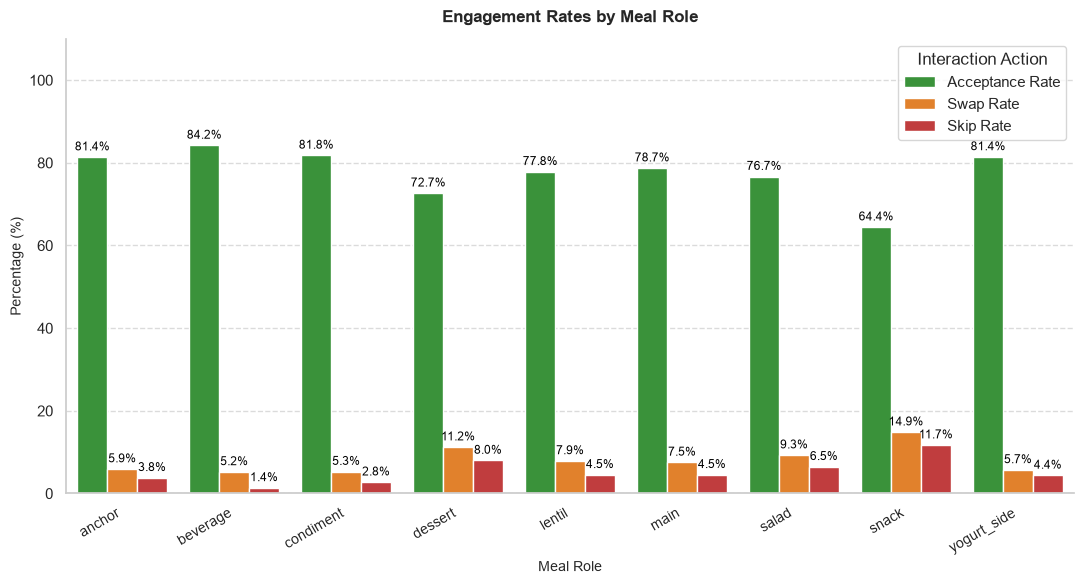

In [22]:
# Query the recipe performance view from the database
query_recipe_perf = "SELECT * FROM v_recipe_performance;"
df_recipe_perf = pd.read_sql(query_recipe_perf, engine)

display(df_recipe_perf.head())

# Aggregate performance metrics by meal role to analyze user behavior per category
df_meal_role_summary = df_recipe_perf.groupby('meal_role').agg({
    'acceptance_rate_pct': 'mean',
    'swap_rate_pct': 'mean',
    'skip_rate_pct': 'mean',
    'total_interactions': 'sum'
}).reset_index()

# Reshape data and format legend labels cleanly
df_melted = df_meal_role_summary.melt(
    id_vars='meal_role', 
    value_vars=['acceptance_rate_pct', 'swap_rate_pct', 'skip_rate_pct'],
    var_name='action',
    value_name='percentage'
)
label_map = {
    'acceptance_rate_pct': 'Acceptance Rate',
    'swap_rate_pct': 'Swap Rate',
    'skip_rate_pct': 'Skip Rate'
}
df_melted['action'] = df_melted['action'].map(label_map)

# Define a custom semantic color palette
semantic_palette = {
    'Acceptance Rate': '#2ca02c',
    'Swap Rate': '#ff7f0e',
    'Skip Rate': '#d62728'
}

# Plot acceptance vs swap vs skip rates by meal role
plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=df_melted,
    x='meal_role',
    y='percentage',
    hue='action',
    palette=semantic_palette
)

plt.title('Engagement Rates by Meal Role', fontsize=12, weight='bold', pad=12)
plt.xlabel('Meal Role', fontsize=10)
plt.ylabel('Percentage (%)', fontsize=10)
plt.ylim(0, 110)
plt.xticks(rotation=30, ha='right', fontsize=10)
plt.legend(title='Interaction Action', frameon=True)

# Add data labels on top of each grouped bar
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{height:.1f}%',
            (p.get_x() + p.get_width() / 2.0, height),
            ha='center',
            va='bottom',
            fontsize=8.5,
            color='black',
            xytext=(0, 3),
            textcoords='offset points'
        )

plt.grid(axis='y', linestyle='--', alpha=0.7)
sns.despine()
plt.tight_layout()
plt.show()

## 2. Most Common Swap Pairs ($A \rightarrow B$ Transitions)
Analyzing the `v_common_swap_pairs` view to identify which dishes users frequently swap away from and what they substitute them with.

,original_recipe_code,original_recipe_name,original_meal_role,swapped_to_recipe_code,swapped_to_recipe_name,swapped_to_meal_role,transition_count
0,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NPM56HSQW8S4...,Jaggery Ghee Cake,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NMXCWEXK5A0S...,Mutton Dum Biryani,None,771
1,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NPM56HSQW8S4...,Jaggery Ghee Cake,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NKJWJY5WX88X...,Moist & Fudgy Chocolate Cake,None,764
2,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NPM56HSQW8S4...,Jaggery Ghee Cake,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NMGHGMPGKQQP...,Mutton Dum Biryani,None,741
3,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NPM56HSQW8S4...,Jaggery Ghee Cake,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NNB88K0DJTSF...,Mutton Dum Biryani,None,738
4,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NPM56HSQW8S4...,Jaggery Ghee Cake,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NSHMM9T70HCS...,Chicken Biryani,None,715
5,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NNB88K0DJTSF...,Mutton Dum Biryani,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NPM56HSQW8S4...,Jaggery Ghee Cake,None,303
6,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NMGHGMPGKQQP...,Mutton Dum Biryani,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NNB88K0DJTSF...,Mutton Dum Biryani,None,290
7,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NNB88K0DJTSF...,Mutton Dum Biryani,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NMGHGMPGKQQP...,Mutton Dum Biryani,None,290
8,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NMXCWEXK5A0S...,Mutton Dum Biryani,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NMGHGMPGKQQP...,Mutton Dum Biryani,None,289
9,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NSHMM9T70HCS...,Chicken Biryani,None,RCP-SHPCXT-EC-20260630-VAGR8Q-01M1NKJWJY5WX88X...,Moist & Fudgy Chocolate Cake,None,289


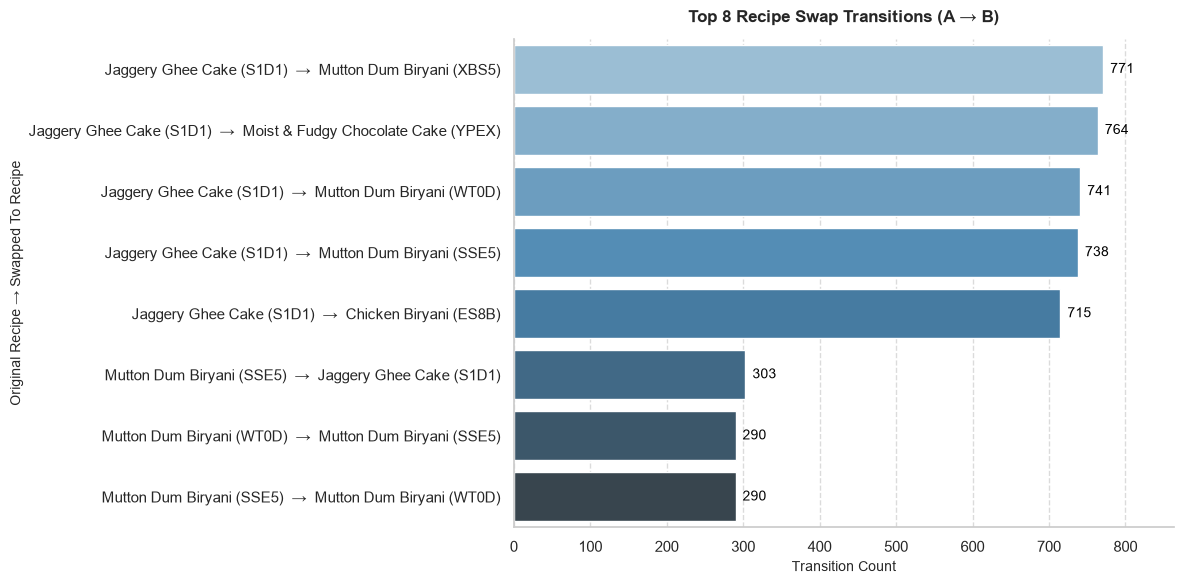

In [23]:
# Query top swap pairs from the view
query_swap_pairs = "SELECT * FROM v_common_swap_pairs LIMIT 10;"
df_swap_pairs = pd.read_sql(query_swap_pairs, engine)

display(df_swap_pairs)

# Create readable transition labels (including short code suffix to distinguish identical dish names)
top_swaps = df_swap_pairs.head(8).copy()
top_swaps['transition_label'] = (
    top_swaps['original_recipe_name'] + ' (' + top_swaps['original_recipe_code'].str[-4:] + ')  →  ' +
    top_swaps['swapped_to_recipe_name'] + ' (' + top_swaps['swapped_to_recipe_code'].str[-4:] + ')'
)

# Plot top transition pairs as a horizontal bar chart
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=top_swaps,
    x='transition_count',
    y='transition_label',
    palette='Blues_d',
    hue='transition_label',
    legend=False
)

plt.title('Top 8 Recipe Swap Transitions (A → B)', fontsize=12, weight='bold', pad=12)
plt.xlabel('Transition Count', fontsize=10)
plt.ylabel('Original Recipe → Swapped To Recipe', fontsize=10)

# Add headroom on the x-axis for data labels
max_count = top_swaps['transition_count'].max()
plt.xlim(0, max_count * 1.12)

# Add data labels to the right of each horizontal bar
for p in ax.patches:
    width = p.get_width()
    ax.annotate(
        f'{int(width):,}',
        (width, p.get_y() + p.get_height() / 2.0),
        ha='left',
        va='center',
        fontsize=10,
        color='black',
        xytext=(5, 0),
        textcoords='offset points'
    )

plt.grid(axis='x', linestyle='--', alpha=0.7)
sns.despine()
plt.tight_layout()
plt.show()

## 3. Plan-to-Order Conversion Rate by Template Goal
Evaluating the `v_template_goal_conversion` view to see how household health goals affect final grocery order conversion.

,template_goal,total_plans_created,total_orders_placed,conversion_rate_pct
0,weight-loss,1287,944,73.35
1,high-protein,1300,895,68.85
2,everyday,1313,725,55.22


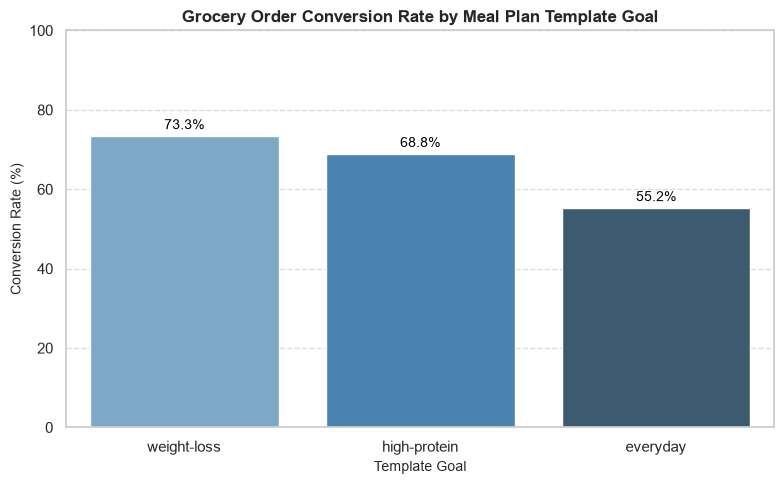

In [24]:
# Query plan-to-order conversion metrics grouped by template goal
query_conversion = "SELECT * FROM v_template_goal_conversion;"
df_conversion = pd.read_sql(query_conversion, engine)

display(df_conversion)

# Plot conversion rates across template goals
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_conversion,
    x='template_goal',
    y='conversion_rate_pct',
    palette='Blues_d',
    hue='template_goal',
    legend=False
)

plt.title(
    'Grocery Order Conversion Rate by Meal Plan Template Goal',
    fontsize=12,
    weight='bold',
)
plt.xlabel('Template Goal', fontsize=10)
plt.ylabel('Conversion Rate (%)', fontsize=10)
plt.ylim(0, 100)

# Add data labels on top of bars
for p in ax.patches:
  ax.annotate(
      f'{p.get_height():.1f}%',
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha='center',
      va='bottom',
      fontsize=10,
      color='black',
      xytext=(0, 3),
      textcoords='offset points',
  )

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 4. Household Repeat-Dish Intervals
Analyzing the `v_household_repeat_intervals` view to examine household fatigue patterns and repetition frequency.

,avg_repeat_interval_days,min_repeat_interval_days,total_repeats_tracked
count,300.000000,300.000000,300.000000
mean,13.852667,1.246667,173.886667
std,14.112447,1.728907,109.673857
min,2.000000,0.000000,33.000000
25%,2.000000,0.000000,46.750000
50%,2.000000,0.000000,267.000000
75%,29.325000,2.000000,267.000000
max,46.800000,8.000000,267.000000


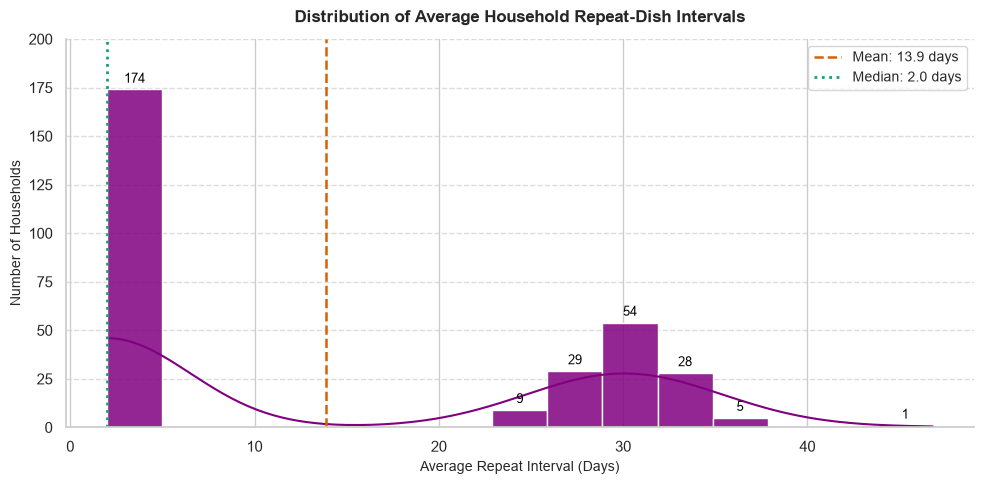

In [25]:
# Query household repeat intervals from the view
query_repeat_intervals = "SELECT * FROM v_household_repeat_intervals;"
df_repeat_intervals = pd.read_sql(query_repeat_intervals, engine)

display(df_repeat_intervals.describe())

# Plot distribution of average repeat intervals across households
plt.figure(figsize=(10, 5))
ax = sns.histplot(
    data=df_repeat_intervals,
    x='avg_repeat_interval_days',
    bins=15,
    kde=True,
    color='purple',
    edgecolor='white',
    alpha=0.85
)

# Calculate mean and median for reference lines
mean_val = df_repeat_intervals['avg_repeat_interval_days'].mean()
median_val = df_repeat_intervals['avg_repeat_interval_days'].median()

plt.axvline(mean_val, color='#d95f02', linestyle='--', linewidth=1.8, label=f'Mean: {mean_val:.1f} days')
plt.axvline(median_val, color='#1b9e77', linestyle=':', linewidth=2.0, label=f'Median: {median_val:.1f} days')

plt.title('Distribution of Average Household Repeat-Dish Intervals', fontsize=12, weight='bold', pad=12)
plt.xlabel('Average Repeat Interval (Days)', fontsize=10)
plt.ylabel('Number of Households', fontsize=10)

# Add count labels above non-empty histogram bars
max_height = max([p.get_height() for p in ax.patches])
plt.ylim(0, max_height * 1.15)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2.0, height),
            ha='center',
            va='bottom',
            fontsize=9,
            color='black',
            xytext=(0, 3),
            textcoords='offset points'
        )

plt.legend(frameon=True, fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
sns.despine()
plt.tight_layout()
plt.show()